# Импорт нужных библиотек

In [1]:
!pip install simpleitk

In [2]:
from keras.models import Model
from keras.layers import Flatten, concatenate, Conv2D, MaxPooling2D, Conv2DTranspose
from keras.layers import Input
from keras import ops
import tensorflow as tf
import os

from keras.layers import BatchNormalization
from keras.layers import Dropout

import matplotlib.pyplot as plt
from glob import glob
import SimpleITK as sitk
import cv2 as cv
import numpy as np
import random as r

# Обзор файлов

In [3]:
path = "/content/Study-NII"

In [4]:
files = sorted(glob(path+"**/*.nii.gz"), key=lambda x: (os.path.splitext(os.path.basename(x))[0]))

len(files)

50

In [5]:
files

['/content/Study-NII/study_0255.nii.gz',
 '/content/Study-NII/study_0256.nii.gz',
 '/content/Study-NII/study_0257.nii.gz',
 '/content/Study-NII/study_0258.nii.gz',
 '/content/Study-NII/study_0259.nii.gz',
 '/content/Study-NII/study_0260.nii.gz',
 '/content/Study-NII/study_0261.nii.gz',
 '/content/Study-NII/study_0262.nii.gz',
 '/content/Study-NII/study_0263.nii.gz',
 '/content/Study-NII/study_0264.nii.gz',
 '/content/Study-NII/study_0265.nii.gz',
 '/content/Study-NII/study_0266.nii.gz',
 '/content/Study-NII/study_0267.nii.gz',
 '/content/Study-NII/study_0268.nii.gz',
 '/content/Study-NII/study_0269.nii.gz',
 '/content/Study-NII/study_0270.nii.gz',
 '/content/Study-NII/study_0271.nii.gz',
 '/content/Study-NII/study_0272.nii.gz',
 '/content/Study-NII/study_0273.nii.gz',
 '/content/Study-NII/study_0274.nii.gz',
 '/content/Study-NII/study_0275.nii.gz',
 '/content/Study-NII/study_0276.nii.gz',
 '/content/Study-NII/study_0277.nii.gz',
 '/content/Study-NII/study_0278.nii.gz',
 '/content/Study

# Обзор первого изображения

In [6]:
itk_img = sitk.ReadImage(files[0])
first_img = sitk.GetArrayFromImage(itk_img)

print(f"shape: {first_img.shape}")
print(f"dtype: {first_img.dtype}")

shape: (38, 512, 512)
dtype: int16


Визуализация первого изображения

'Так как изображения являются результатом визуализации КТ снимков, то и ориентиром является ось x'

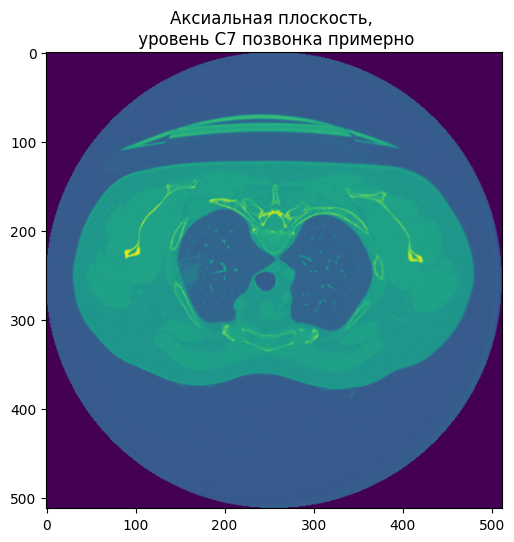

In [7]:
fig = plt.figure(figsize=(20,15))

ax1 = fig.add_subplot(1,3,1)
ax1.imshow(first_img[30,:,:])
plt.title("Аксиальная плоскость, \n уровень C7 позвонка примерно", fontsize = 12)

'''Так как изображения являются результатом визуализации КТ снимков, то и ориентиром является ось x'''

# Обзор первого сегментированного изображения

In [8]:
files[0]

'/content/Study-NII/study_0255.nii.gz'

In [9]:
seg_img = sitk.ReadImage('/content/Masks-NII/study_0255_mask.nii.gz')
first_seg_img = sitk.GetArrayFromImage(seg_img)

print(f"shape: {first_seg_img.shape}")
print(f"dtype: {first_seg_img.dtype}")

shape: (38, 512, 512)
dtype: int16


Визуализация первого сегментированного изображения

Text(0.5, 1.0, 'Аксиальная плоскость')

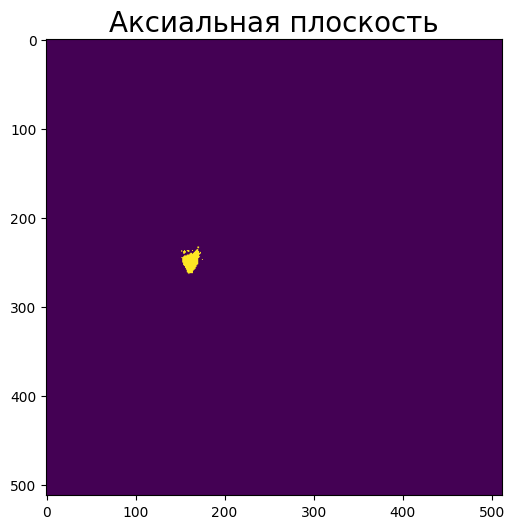

In [10]:
fig = plt.figure(figsize=(20,15))

ax1 = fig.add_subplot(1,3,1)
ax1.imshow(first_seg_img[30,:,:])
plt.title("Аксиальная плоскость", fontsize=20)

# Функция конвертации изображения в массив

In [11]:
def to_array(path, end):

    files = sorted(glob(path+end, recursive=True), key=lambda x: (os.path.splitext(os.path.basename(x))[0]))
    print(files)

    img_list = []

    for file in files:
        img = sitk.ReadImage(file)
        img = sitk.GetArrayFromImage(img)
        img = ((img - img.min())/(img.max() - img.min()))
        img.astype("float32")

        for slice in range(10, 30):
            img_s = img[slice,:,:]
            img_s = np.expand_dims(img_s, axis=-1)
            img_list.append(img_s)

    return np.array(img_list, np.float32)

# Применение функции to_array

In [12]:
lungs = to_array(path=path, end="**/*.nii.gz")

['/content/Study-NII/study_0255.nii.gz', '/content/Study-NII/study_0256.nii.gz', '/content/Study-NII/study_0257.nii.gz', '/content/Study-NII/study_0258.nii.gz', '/content/Study-NII/study_0259.nii.gz', '/content/Study-NII/study_0260.nii.gz', '/content/Study-NII/study_0261.nii.gz', '/content/Study-NII/study_0262.nii.gz', '/content/Study-NII/study_0263.nii.gz', '/content/Study-NII/study_0264.nii.gz', '/content/Study-NII/study_0265.nii.gz', '/content/Study-NII/study_0266.nii.gz', '/content/Study-NII/study_0267.nii.gz', '/content/Study-NII/study_0268.nii.gz', '/content/Study-NII/study_0269.nii.gz', '/content/Study-NII/study_0270.nii.gz', '/content/Study-NII/study_0271.nii.gz', '/content/Study-NII/study_0272.nii.gz', '/content/Study-NII/study_0273.nii.gz', '/content/Study-NII/study_0274.nii.gz', '/content/Study-NII/study_0275.nii.gz', '/content/Study-NII/study_0276.nii.gz', '/content/Study-NII/study_0277.nii.gz', '/content/Study-NII/study_0278.nii.gz', '/content/Study-NII/study_0279.nii.gz',

In [13]:
lungs.shape # Формат NWHC

(1000, 512, 512, 1)

Text(0.5, 1.0, 'Лёгкие: 300')

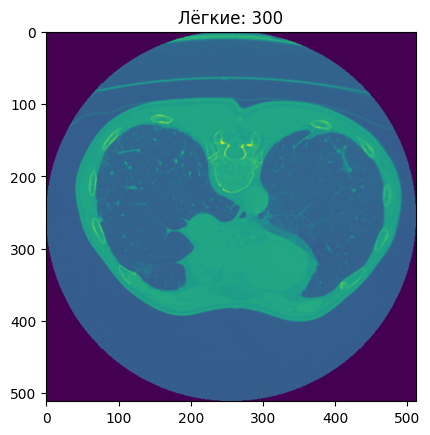

In [14]:
plt.imshow(lungs[300,:,:,-1])
plt.title("Лёгкие: 300")

# Сегментированные изображения

In [15]:
first_seg_img.shape

(38, 512, 512)

Text(0.5, 1.0, '"Матовое стекло"')

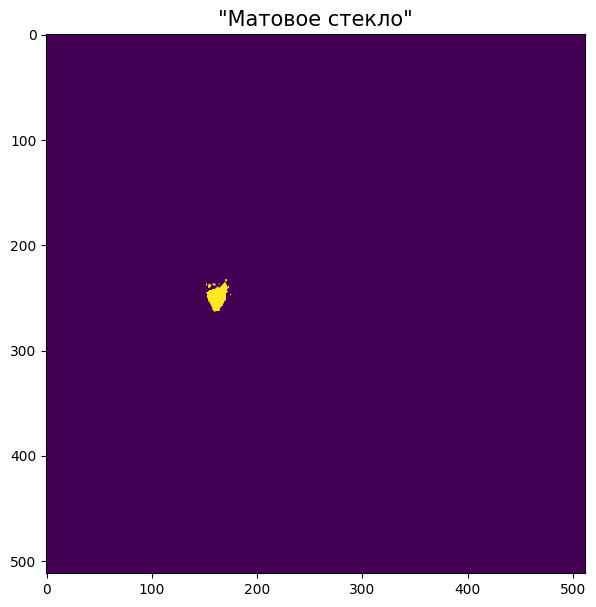

In [16]:
plt.figure(figsize=(7,7))
plt.imshow(first_seg_img[30,:,:])
plt.title('"Матовое стекло"', fontsize=15)

# Функция конвертации сегментированных изображений в массив

In [17]:
def seg_to_array(path, end):

    files = sorted(glob(path+end, recursive=True), key=lambda x: (os.path.splitext(os.path.basename(x))[0]))
    print(files)

    img_list = []

    for file in files:
        img = sitk.ReadImage(file)
        img = sitk.GetArrayFromImage(img)

        img.astype("float32")

        for slice in range(10, 30):
            img_s = img[slice,:,:]
            img_s = np.expand_dims(img_s, axis=-1)
            img_list.append(img_s)

    return np.array(img_list, np.float32)

In [18]:
seg_matt_glass = seg_to_array(path="/content/Masks-NII", end="**/*_mask.nii.gz")

['/content/Masks-NII/study_0255_mask.nii.gz', '/content/Masks-NII/study_0256_mask.nii.gz', '/content/Masks-NII/study_0257_mask.nii.gz', '/content/Masks-NII/study_0258_mask.nii.gz', '/content/Masks-NII/study_0259_mask.nii.gz', '/content/Masks-NII/study_0260_mask.nii.gz', '/content/Masks-NII/study_0261_mask.nii.gz', '/content/Masks-NII/study_0262_mask.nii.gz', '/content/Masks-NII/study_0263_mask.nii.gz', '/content/Masks-NII/study_0264_mask.nii.gz', '/content/Masks-NII/study_0265_mask.nii.gz', '/content/Masks-NII/study_0266_mask.nii.gz', '/content/Masks-NII/study_0267_mask.nii.gz', '/content/Masks-NII/study_0268_mask.nii.gz', '/content/Masks-NII/study_0269_mask.nii.gz', '/content/Masks-NII/study_0270_mask.nii.gz', '/content/Masks-NII/study_0271_mask.nii.gz', '/content/Masks-NII/study_0272_mask.nii.gz', '/content/Masks-NII/study_0273_mask.nii.gz', '/content/Masks-NII/study_0274_mask.nii.gz', '/content/Masks-NII/study_0275_mask.nii.gz', '/content/Masks-NII/study_0276_mask.nii.gz', '/content

In [19]:
seg_matt_glass.shape

(1000, 512, 512, 1)

Text(0.5, 1.0, 'lungs:300')

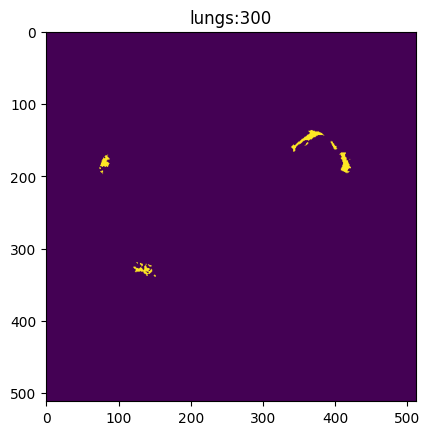

In [20]:
plt.imshow(seg_matt_glass[300,:,:,-1])
plt.title("lungs:300")

# Визуализация изображений

Text(0.5, 1.0, 'segmentation image')

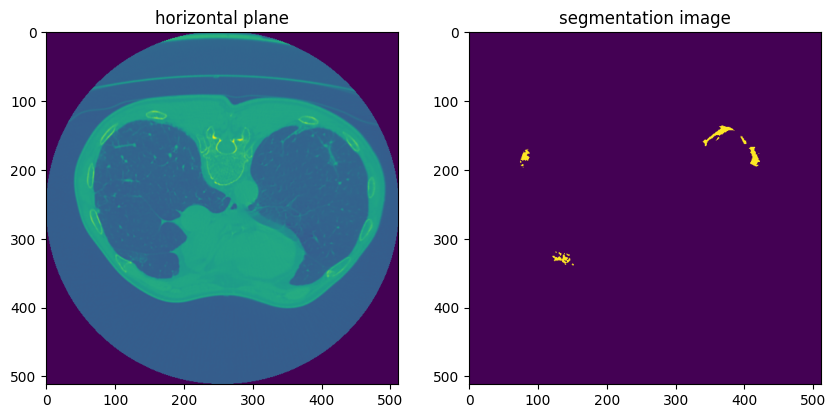

In [21]:
idx = 300

plt.figure(figsize=(10,10))

plt.subplot(1,2,1)
plt.imshow(lungs[idx,:,:,-1])
plt.title("horizontal plane")

plt.subplot(1,2,2)
plt.imshow(seg_matt_glass[idx,:,:,-1])
plt.title("segmentation image")

# Массивы для U-NET Модели

In [22]:
lungs = to_array(path=path, end="**/*.nii.gz")
seg = seg_to_array(path="/content/Masks-NII", end="**/*_mask.nii.gz")

['/content/Study-NII/study_0255.nii.gz', '/content/Study-NII/study_0256.nii.gz', '/content/Study-NII/study_0257.nii.gz', '/content/Study-NII/study_0258.nii.gz', '/content/Study-NII/study_0259.nii.gz', '/content/Study-NII/study_0260.nii.gz', '/content/Study-NII/study_0261.nii.gz', '/content/Study-NII/study_0262.nii.gz', '/content/Study-NII/study_0263.nii.gz', '/content/Study-NII/study_0264.nii.gz', '/content/Study-NII/study_0265.nii.gz', '/content/Study-NII/study_0266.nii.gz', '/content/Study-NII/study_0267.nii.gz', '/content/Study-NII/study_0268.nii.gz', '/content/Study-NII/study_0269.nii.gz', '/content/Study-NII/study_0270.nii.gz', '/content/Study-NII/study_0271.nii.gz', '/content/Study-NII/study_0272.nii.gz', '/content/Study-NII/study_0273.nii.gz', '/content/Study-NII/study_0274.nii.gz', '/content/Study-NII/study_0275.nii.gz', '/content/Study-NII/study_0276.nii.gz', '/content/Study-NII/study_0277.nii.gz', '/content/Study-NII/study_0278.nii.gz', '/content/Study-NII/study_0279.nii.gz',

In [23]:
lungs.shape, seg.shape

((1000, 512, 512, 1), (1000, 512, 512, 1))

Text(0.5, 1.0, 'segmentation image')

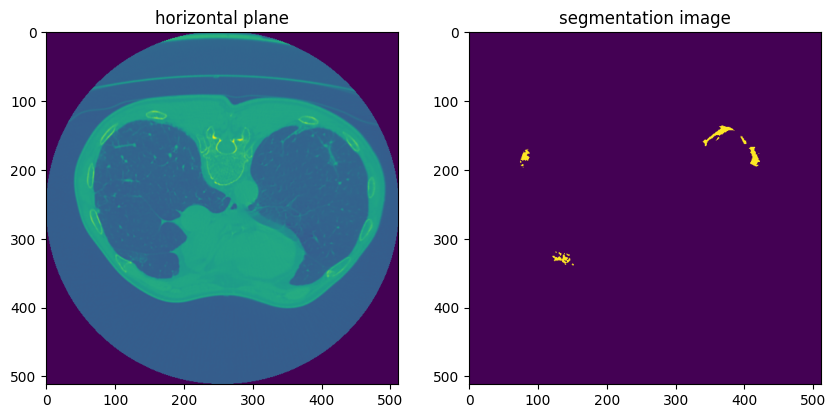

In [24]:
idx = 300

plt.figure(figsize=(10,10))

plt.subplot(1,2,1)
plt.imshow(lungs[idx,:,:,-1])
plt.title("horizontal plane")

plt.subplot(1,2,2)
plt.imshow(seg[idx,:,:,-1])
plt.title("segmentation image")

# Фильтрация массивов с маской и без

In [25]:
def array_filter(data_x, data_y):

  lungs_mg = []
  seg_mg = []


  lungs_clear = []
  seg_clear = []


  for i,_ in enumerate(data_y):
    if data_y[i].min() < data_y[i].max():
      lungs_mg.append(data_x[i])
      seg_mg.append(data_y[i])

    if data_y[i].min() == data_y[i].max():
      lungs_clear.append(data_x[i])
      seg_clear.append(data_y[i])

  return np.array(lungs_mg), np.array(seg_mg), np.array(lungs_clear), np.array(seg_clear)

In [26]:
lungs_mg, seg_mg, lungs_clear, seg_clear = array_filter(lungs, seg)

In [27]:
# Срезы с КТ признаками ковид
lungs_mg.shape, seg_mg.shape

((609, 512, 512, 1), (609, 512, 512, 1))

In [28]:
# КТ признаков ковид нет
lungs_clear.shape, seg_clear.shape

((391, 512, 512, 1), (391, 512, 512, 1))

In [29]:
# В функцию подаются массивы изображений с матовым стеклом
def ct_filter(data_x, data_y):
  # Массивы с поражением легких менее 25% (КТ1)
  lungs_ct1 = []
  seg_ct1 = []

  # Массивы с поражением легких 25-50% (КТ2)
  lungs_ct2 = []
  seg_ct2 = []

  # Массивы с поражением легких 50-75% (КТ3)
  lungs_ct3 = []
  seg_ct3 = []

  # Массивы с поражением легких 75-100% (КТ4)
  lungs_ct4 = []
  seg_ct4 = []

  # Итератор проходит каждый элемент в значении data_y
  for i,_ in enumerate(data_y):
    # В каждом элементе data_y вычисляется количество не нулевых пикселей
    count_value_els = np.count_nonzero(data_y[i])

    # Если count меньше 25% от общего количества пикселей (4000)
    if count_value_els <= 1000:
      # То срез и сегментированное изображение добавляются в массивы с КТ1
      lungs_ct1.append(data_x[i])
      seg_ct1.append(data_y[i])

    # Если count больше 25% и меньше 50% от общего количества пикселей (4000)
    if (count_value_els > 1000) & (count_value_els <= 2000):
      # То срез и сегментированное изображение добавляются в массивы с КТ2
      lungs_ct2.append(data_x[i])
      seg_ct2.append(data_y[i])

    # Если count больше 50% и меньше 75% от общего количества пикселей (4000)
    if (count_value_els > 2000) & (count_value_els <= 3000):
      # То срез и сегментированное изображение добавляются в массивы с КТ3
      lungs_ct3.append(data_x[i])
      seg_ct3.append(data_y[i])

    # Если count больше 75% и меньше 100% от общего количества пикселей (4000)
    if (count_value_els > 3000) & (count_value_els <= 4000):
      # То срез и сегментированное изображение добавляются в массивы с КТ4
      lungs_ct4.append(data_x[i])
      seg_ct4.append(data_y[i])

  return np.array(lungs_ct1), np.array(seg_ct1), np.array(lungs_ct2), np.array(seg_ct2), np.array(lungs_ct3), np.array(seg_ct3), np.array(lungs_ct4), np.array(seg_ct4)

In [30]:
lungs_ct1, seg_ct1, lungs_ct2, seg_ct2, lungs_ct3, seg_ct3, lungs_ct4, seg_ct4 = ct_filter(lungs_mg, seg_mg)

In [31]:
lungs_ct1.shape, seg_ct1.shape

((313, 512, 512, 1), (313, 512, 512, 1))

In [32]:
lungs_ct2.shape, seg_ct2.shape

((130, 512, 512, 1), (130, 512, 512, 1))

In [33]:
lungs_ct3.shape, seg_ct3.shape

((96, 512, 512, 1), (96, 512, 512, 1))

In [34]:
lungs_ct4.shape, seg_ct4.shape

((38, 512, 512, 1), (38, 512, 512, 1))

/tmp/ipykernel_11239/3843757509.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10,10))


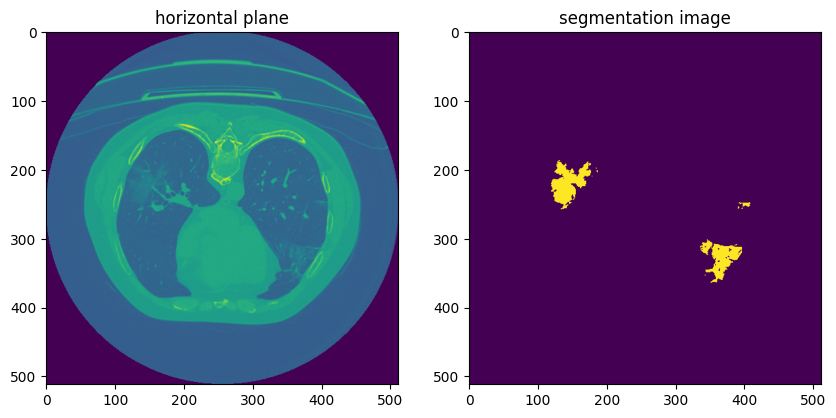

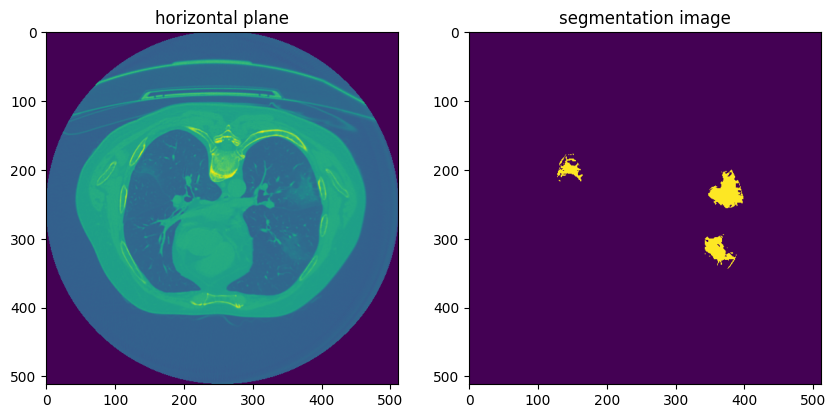

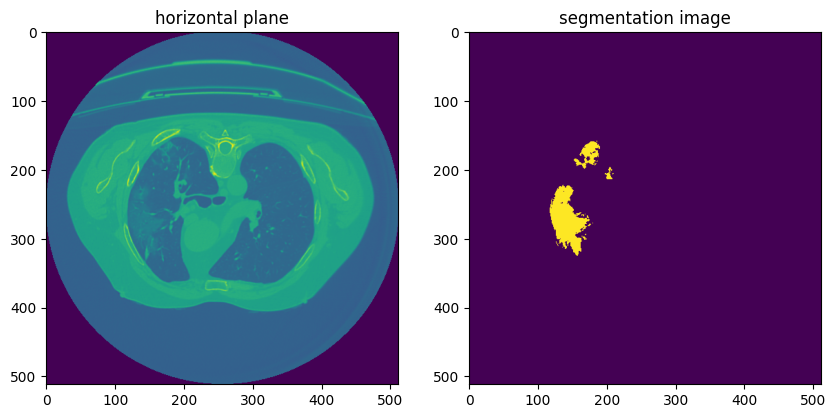

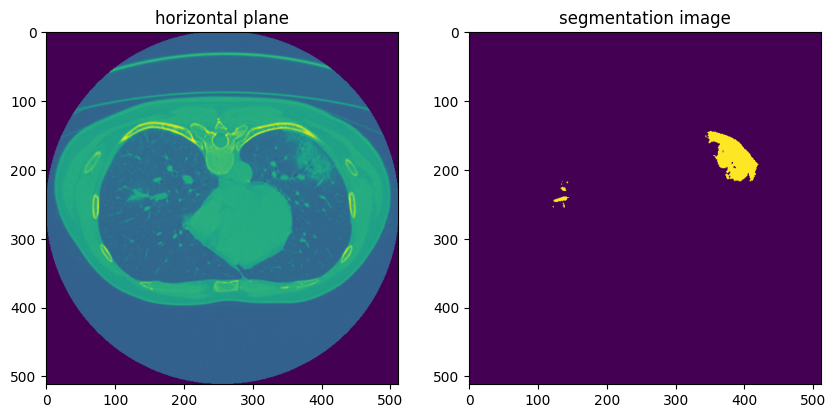

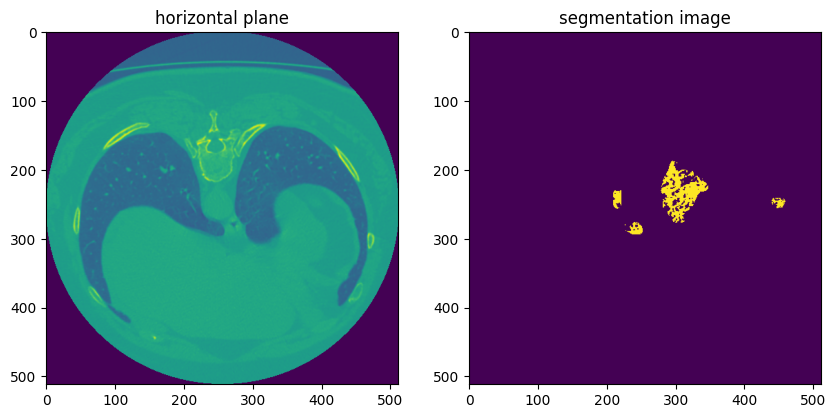

...

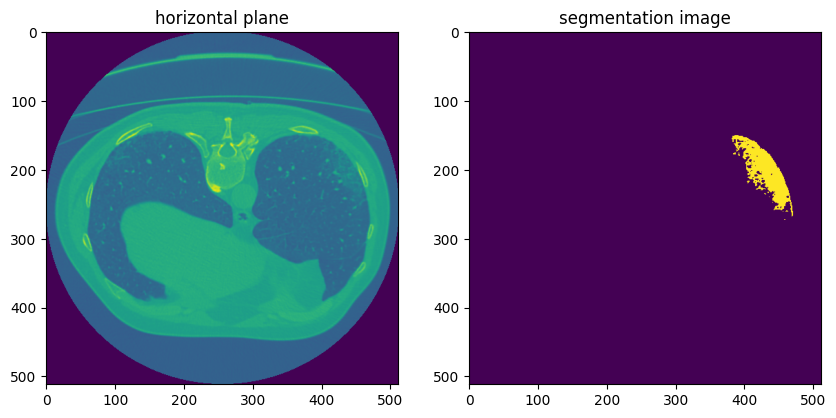

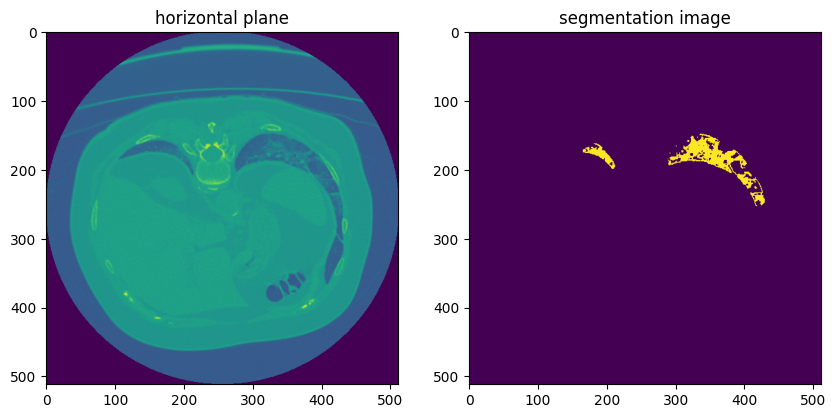

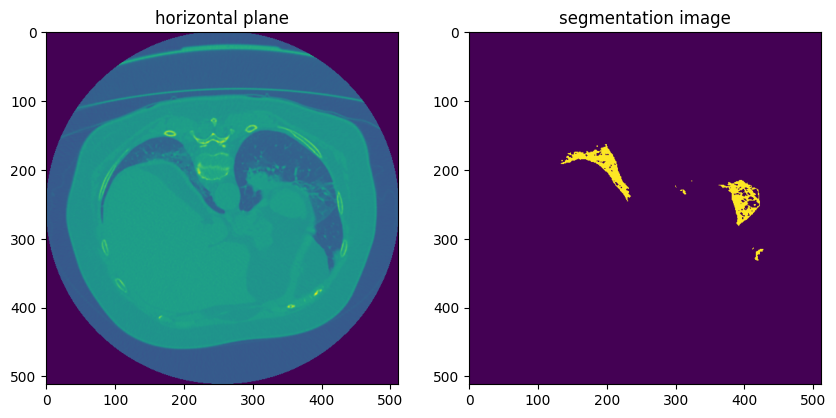

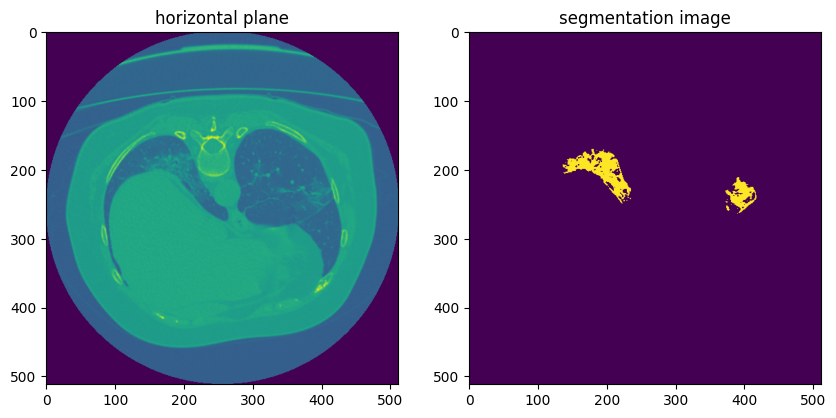

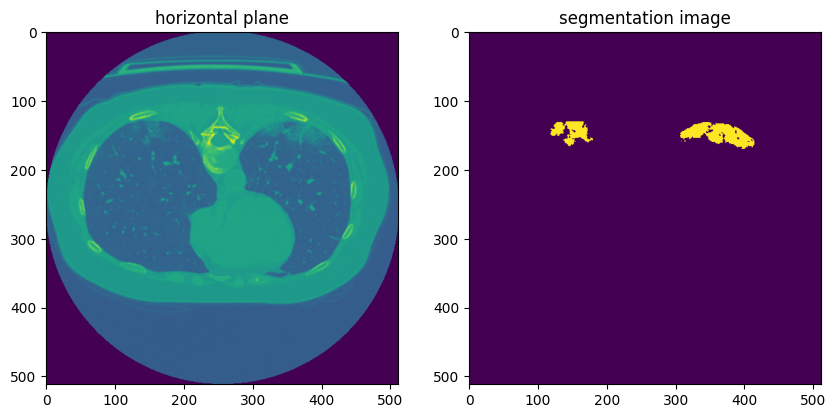

In [35]:
idx = 0
while idx < len(lungs_ct4):
  plt.figure(figsize=(10,10))

  plt.subplot(1,2,1)
  plt.imshow(lungs_ct4[idx,:,:,-1])
  plt.title("horizontal plane")

  plt.subplot(1,2,2)
  plt.imshow(seg_ct4[idx,:,:,-1])
  plt.title("segmentation image")
  idx = idx + 1

# Срезы

In [36]:
# Тренировочный набор
lungs_train_ct1 = lungs_ct1[:96]
seg_train_ct1 = seg_ct1[:96]

lungs_train_ct2 = lungs_ct2[:96]
seg_train_ct2 = seg_ct2[:96]

# Объединение в тренировочный набор срезов и масок
lungs_train = np.concatenate((lungs_train_ct1, lungs_train_ct2))
seg_train = np.concatenate((seg_train_ct1, seg_train_ct2))

In [37]:
# Оценочный набор
lungs_val_ct1 = lungs_ct1[96:128]
seg_val_ct1 = seg_ct1[96:128]

lungs_val_ct2 = lungs_ct2[96:128]
seg_val_ct2 = seg_ct2[96:128]

# Объединение в оценочный набор срезов и масок
lungs_val = np.concatenate((lungs_val_ct1, lungs_val_ct2))
seg_val = np.concatenate((seg_val_ct1, seg_val_ct2))

In [51]:
# Тестовый набор
lungs_test = lungs_ct1[128:192]
seg_test = seg_ct1[128:192]

In [39]:
lungs_train.shape, seg_train.shape

((192, 512, 512, 1), (192, 512, 512, 1))

In [40]:
lungs_val.shape, seg_val.shape

((64, 512, 512, 1), (64, 512, 512, 1))

In [41]:
lungs_test.shape, seg_test.shape

((64, 512, 512, 1), (64, 512, 512, 1))

/tmp/ipykernel_11239/1931582034.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10,10))


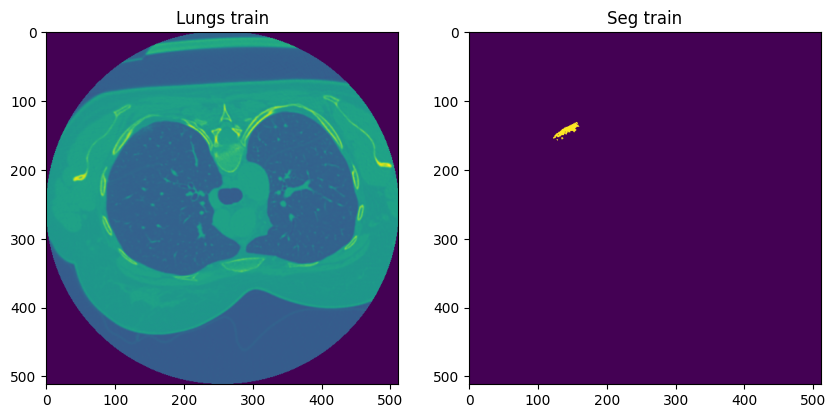

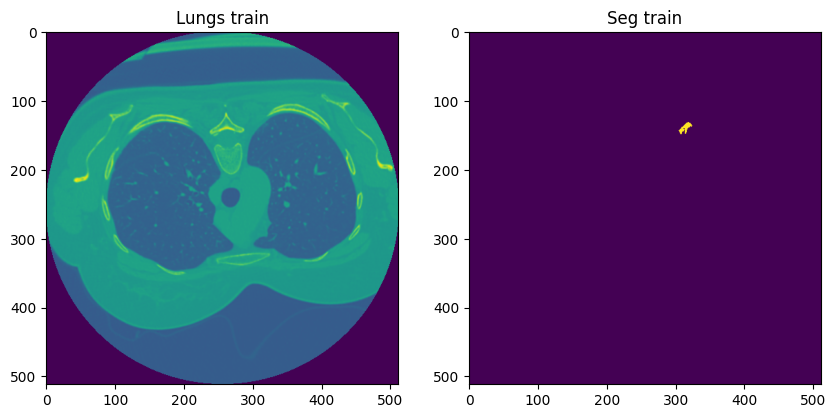

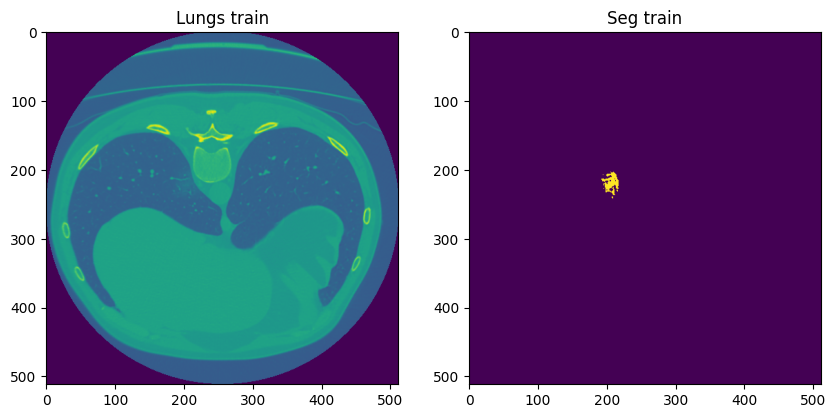

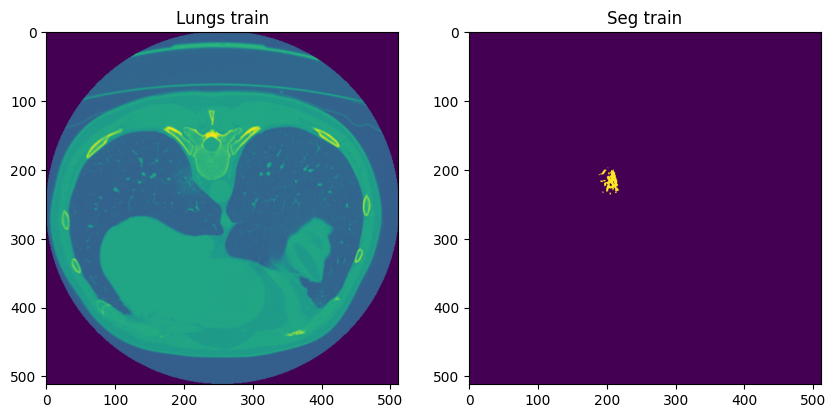

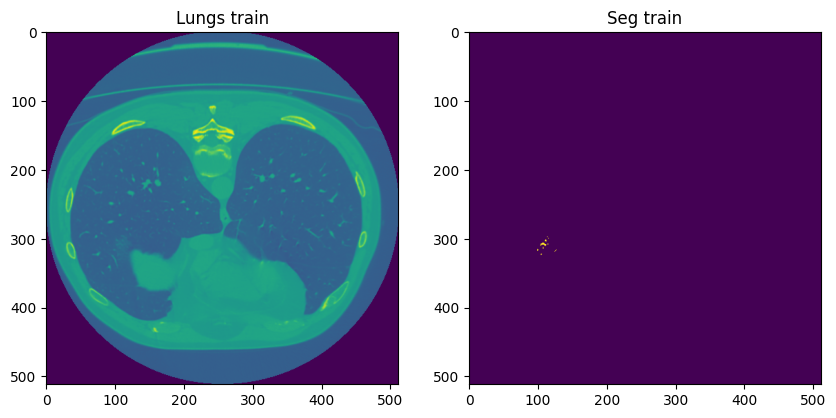

...

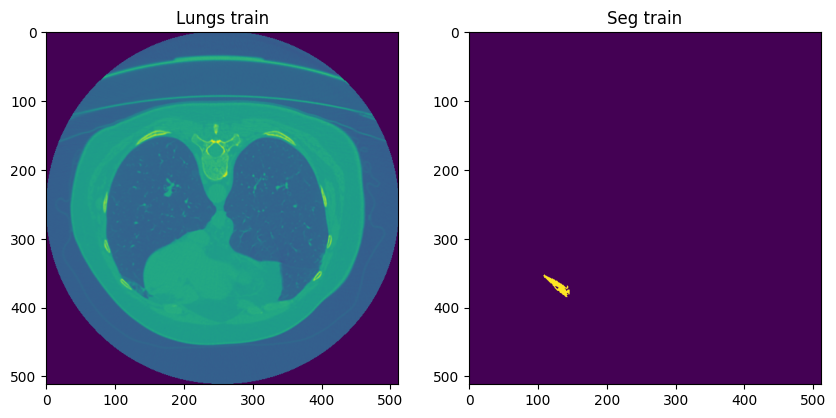

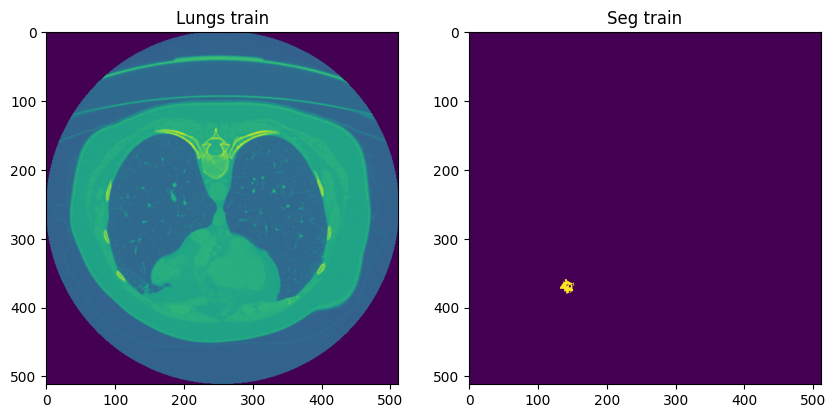

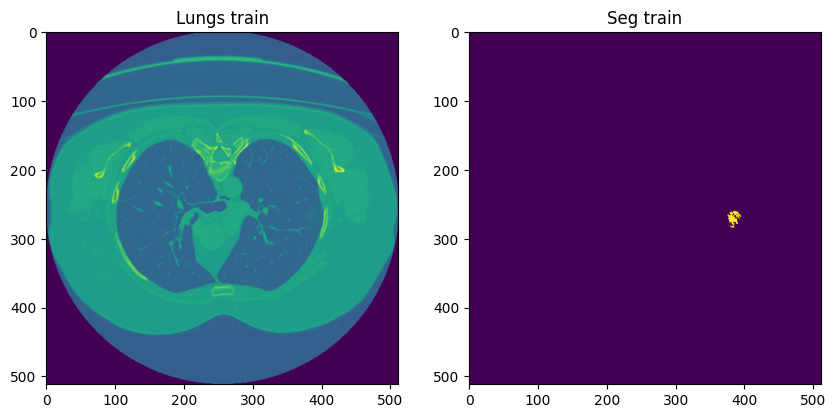

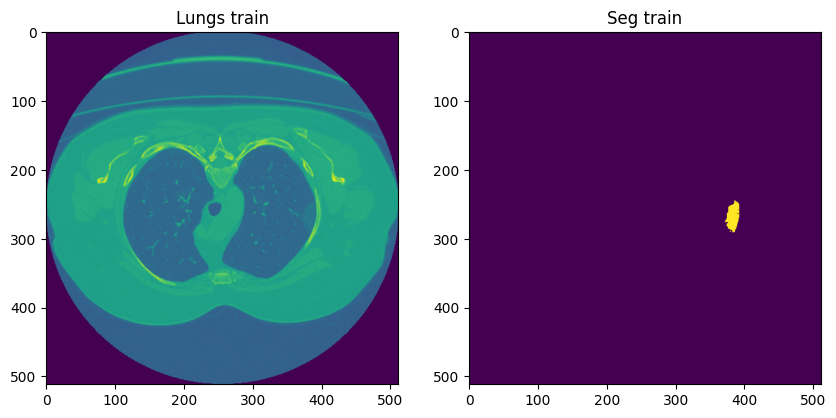

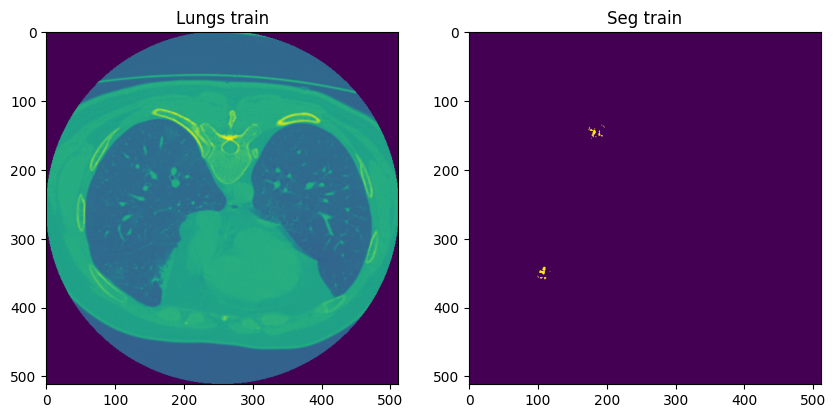

In [42]:
idx = 0
while idx < len(lungs_test):
  plt.figure(figsize=(10,10))

  plt.subplot(1,2,1)
  plt.imshow(lungs_test[idx,:,:,-1])
  plt.title("Lungs train")

  plt.subplot(1,2,2)
  plt.imshow(seg_test[idx,:,:,-1])
  plt.title("Seg train")
  idx = idx + 1

# **U-NET Модель**

In [56]:
def IoU_coef(y_true, y_pred):
    y_true = ops.cast(y_true, dtype="float32")
    y_pred = ops.cast(y_pred, dtype="float32")

    T = ops.reshape(y_true, [-1])
    P = ops.reshape(y_pred, [-1])

    intersection = ops.sum(T * P)

    IoU = (intersection + 1.0) / (ops.sum(T) + ops.sum(P) - intersection + 1.0)

    return IoU

In [57]:
def IoU_loss(y_true, y_pred):
    return 1-IoU_coef(y_true, y_pred)

In [45]:
def unet():
    inputs = Input((512, 512, 1)) # Input layer

    #----Encoder----#
    # Block 1
    conv1 = Conv2D(2, (3, 3), activation='relu', padding='same') (inputs)
    conv1 = Conv2D(2, (3, 3), activation='relu', padding='same') (conv1)

    # Block 2
    pool1 = MaxPooling2D((2, 2)) (conv1)
    conv2 = Conv2D(4, (3, 3), activation='relu', padding='same') (pool1)
    conv2 = Conv2D(4, (3, 3), activation='relu', padding='same') (conv2)

    # Block 3
    pool2 = MaxPooling2D((2, 2)) (conv2)
    conv3 = Conv2D(8, (3, 3), activation='relu', padding='same') (pool2)
    conv3 = Conv2D(8, (3, 3), activation='relu', padding='same') (conv3)

    # Block 4
    pool3 = MaxPooling2D((2, 2))(conv3)
    conv4 = Conv2D(16, (3, 3), activation='relu', padding='same') (pool3)
    conv4 = Conv2D(16, (3, 3), activation='relu', padding='same') (conv4)
    #----Encoder----#

    # Intermediate Block
    pool4 = MaxPooling2D((2, 2))(conv4)
    conv5 = Conv2D(32, (3, 3), activation='relu', padding='same') (pool4)
    conv5 = Conv2D(32, (3, 3), activation='relu', padding='same') (conv5)

    #----Decoder----#
    # Block 1
    up6 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same') (conv5)
    up6 = concatenate([up6, conv4], axis=-1)
    conv6 = Conv2D(16, (3, 3), activation='relu', padding='same') (up6)
    conv6 = Conv2D(16, (3, 3), activation='relu', padding='same') (conv6)

    # Block 2
    up7 = Conv2DTranspose(8, (2, 2), strides=(2, 2), padding='same') (conv6)
    up7 = concatenate([up7, conv3], axis=-1)
    conv7 = Conv2D(8, (3, 3), activation='relu', padding='same') (up7)
    conv7 = Conv2D(8, (3, 3), activation='relu', padding='same') (conv7)

    # Block 3
    up8 = Conv2DTranspose(4, (2, 2), strides=(2, 2), padding='same') (conv7)
    up8 = concatenate([up8, conv2], axis=-1)
    conv8 = Conv2D(4, (3, 3), activation='relu', padding='same') (up8)
    conv8 = Conv2D(4, (3, 3), activation='relu', padding='same') (conv8)

    # Block 4
    up9 = Conv2DTranspose(2, (2, 2), strides=(2, 2), padding='same') (conv8)
    up9 = concatenate([up9, conv1], axis=-1)
    conv9 = Conv2D(2, (3, 3), activation='relu', padding='same') (up9)
    conv9 = Conv2D(2, (3, 3), activation='relu', padding='same') (conv9)

    conv10 = Conv2D(1, (1, 1), activation='sigmoid')(conv9)

    model = Model(inputs=inputs, outputs=conv10)

    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss=IoU_loss,
                  metrics=[IoU_coef])

    return model

In [46]:
model = unet()




In [47]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [48]:
BATCH_SIZE = 32
TRAIN_SIZE = len(lungs_train)
VALIDATION_SIZE = len(lungs_val)

In [69]:
EPOCHS = 20
STEPS_PER_EPOCH = TRAIN_SIZE // BATCH_SIZE
VALIDATION_STEP = VALIDATION_SIZE // BATCH_SIZE

In [53]:
history = model.fit(lungs_train, seg_train,
          epochs=EPOCHS,
          steps_per_epoch=STEPS_PER_EPOCH,
          shuffle = True,
          validation_data = (lungs_val, seg_val),
          validation_steps= VALIDATION_STEP,
          verbose=2)

Epoch 1/20
6/6 - 124s - 21s/step - io_u_coef: 0.0041 - loss: 0.9959 - val_io_u_coef: 0.0042 - val_loss: 0.9958
Epoch 2/20
6/6 - 124s - 21s/step - io_u_coef: 0.0043 - loss: 0.9957 - val_io_u_coef: 0.0044 - val_loss: 0.9956
Epoch 3/20
6/6 - 116s - 19s/step - io_u_coef: 0.0045 - loss: 0.9955 - val_io_u_coef: 0.0046 - val_loss: 0.9954
Epoch 4/20
6/6 - 117s - 20s/step - io_u_coef: 0.0047 - loss: 0.9953 - val_io_u_coef: 0.0047 - val_loss: 0.9953
Epoch 5/20
6/6 - 124s - 21s/step - io_u_coef: 0.0048 - loss: 0.9952 - val_io_u_coef: 0.0046 - val_loss: 0.9954
Epoch 6/20
6/6 - 141s - 24s/step - io_u_coef: 0.0048 - loss: 0.9952 - val_io_u_coef: 0.0046 - val_loss: 0.9954
Epoch 7/20
6/6 - 142s - 24s/step - io_u_coef: 0.0048 - loss: 0.9952 - val_io_u_coef: 0.0047 - val_loss: 0.9953
Epoch 8/20
6/6 - 144s - 24s/step - io_u_coef: 0.0049 - loss: 0.9951 - val_io_u_coef: 0.0048 - val_loss: 0.9952
Epoch 9/20
6/6 - 123s - 20s/step - io_u_coef: 0.0049 - loss: 0.9951 - val_io_u_coef: 0.0047 - val_loss: 0.9953
E

# График обучения

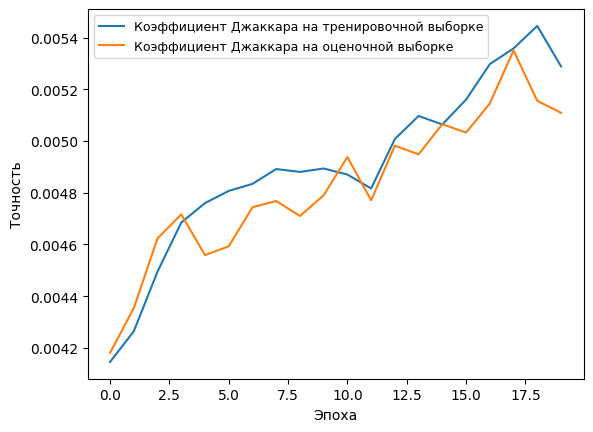

In [68]:
plt.plot(history.history['io_u_coef'], label='Коэффициент Джаккара на тренировочной выборке')
plt.plot(history.history['val_io_u_coef'], label='Коэффициент Джаккара на оценочной выборке')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend(loc=2, fontsize=9)

In [70]:
test_loss, test_acc = model.evaluate(lungs_test, seg_test, verbose=2)

2/2 - 14s - 7s/step - io_u_coef: 0.0022 - loss: 0.9978


In [71]:
print(test_acc*100)

0.21904273889958858


# Предсказывание

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 762ms/step


Text(0.5, 1.0, 'Predict')

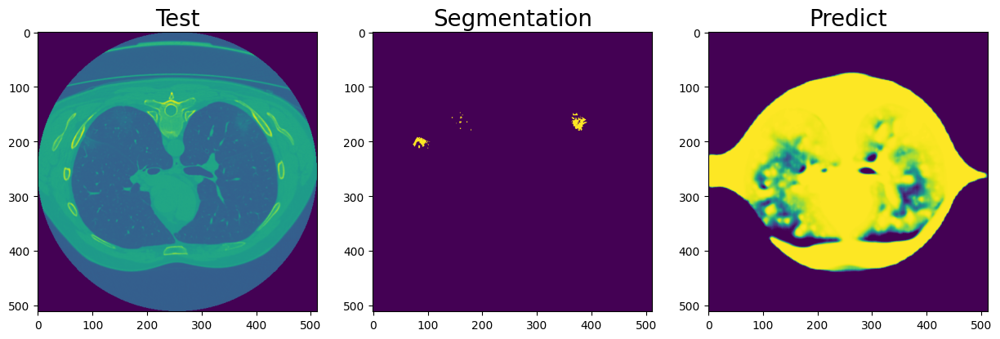

In [72]:
x = 15
sample = np.expand_dims(lungs_test[x], axis=0)
pred = model.predict(sample)

fig = plt.figure(figsize=(15,15))

plt.subplot(1,3,1)
plt.imshow(lungs_test[x,:,:,-1])
plt.title("Test", fontsize = 20)

plt.subplot(1,3,2)
plt.imshow(seg_test[x,:,:,-1])
plt.title("Segmentation", fontsize = 20)

plt.subplot(1,3,3)
plt.imshow(pred[0,:,:,-1])
plt.title("Predict", fontsize = 20)